# InceptionV3 — Transfer Learning for Brain MRI Tumor Detection

This notebook follows the same pipeline as `VGG16.ipynb` (dataset download →
preprocessing → training → evaluation) but uses the **InceptionV3** architecture with
ImageNet transfer learning.

**Dataset:** [Brain Tumor MRI Dataset (Kaggle)](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset)
— 4 classes: glioma, meningioma, notumor, pituitary.

**What this notebook does differently from the VGG16 baseline**

1. **Architecture-specific preprocessing** — InceptionV3 uses factorized convolutions and auxiliary Towers (Inception modules) to keep computation efficient at ~23.9M parameters.
   Each pretrained backbone needs its own input scaling (see the Model
   Architecture section). The preprocessing is embedded *inside* the model, so
   the saved `model.keras` is **drop-in compatible with the deployed website**:
   the apps feed `[0,1]` RGB at 128x128 and this model accepts exactly that.
2. **Class order fixed to the deployment order** —
   `["meningioma", "pituitary", "notumor", "glioma"]` (the order the website
   uses; verified against the existing VGG16 model which scores 91.0% on the
   official test set under this order).
3. **Validation split + class weights + EarlyStopping/ModelCheckpoint/ReduceLROnPlateau** —
   the VGG16 baseline trained on 100% of the data with no validation set; here a
   stratified 10% validation split guards against overfitting, and class weights
   handle the mild class imbalance (notumor is the smallest class).
4. **Two-stage training** — stage 1 trains only the new classification head on a
   frozen backbone; stage 2 unfreezes the top conv layers and fine-tunes at a
   100x smaller learning rate.
5. **GlobalAveragePooling head** instead of Flatten — far fewer parameters,
   less overfitting, resolution-robust.

**Resolution note:** we train at 128x128 to match the deployed app's hardcoded
`IMAGE_SIZE = (128, 128)`. The backbones remain usable at this resolution; if
you ever change the app to 224x224, raise `IMAGE_SIZE` here and retrain.

**Smoke mode:** the notebook also honours `MRI_SMOKE=1` (tiny subset, 2 epochs,
artifacts to `smoke_runs/InceptionV3/`) so the full pipeline can be validated quickly
on CPU. Real results must come from a full run (GPU recommended).


## Import Libraries and Tools

In [1]:
import os
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PIL.Image as Image
import PIL.ImageEnhance as ImageEnhance
import tensorflow as tf
import keras

# Matches the deployed apps' hardcoded IMAGE_SIZE = (128, 128)
IMAGE_SIZE = 128

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, GlobalAveragePooling2D, Rescaling, BatchNormalization,
)
from tensorflow.keras.utils import load_img
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, ReduceLROnPlateau,
)
from tensorflow.keras.applications import InceptionV3

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import label_binarize

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# Deployment-compatible class order (matches the website's CLASS_NAMES).
# Verified: the existing VGG16 model scores 0.9100 on the official test set
# under exactly this order.
CLASS_NAMES = ["meningioma", "pituitary", "notumor", "glioma"]

# Smoke mode: set MRI_SMOKE=1 to validate the pipeline quickly (tiny subset,
# 2 epochs, artifacts saved to smoke_runs/InceptionV3/ instead of InceptionV3_model/).
SMOKE = os.environ.get("MRI_SMOKE", "0") == "1"

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Smoke mode:", SMOKE)


I0000 00:00:1794420714.286339   37761 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794420714.288105   37761 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794420714.391321   37761 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794420718.012994   37761 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794420718.013994   37761 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.22.0-rc0 | Keras: 3.16.0.dev2026101404
Smoke mode: True


## Local Dataset

In [2]:
%pip install kagglehub -q


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
import kagglehub

# Download latest version (cached locally after the first download)
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", path)

Path to dataset files: /home/nishanta/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


In [4]:
train_dir = os.path.join(path, "Training")
test_dir = os.path.join(path, "Testing")

# Load and shuffle the train data
train_paths = []
train_labels = []
for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
        train_paths.append(os.path.join(train_dir, label, image))
        train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels, random_state=SEED)

# Load and shuffle the test data (kept untouched until final evaluation)
test_paths = []
test_labels = []
for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
        test_paths.append(os.path.join(test_dir, label, image))
        test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels, random_state=SEED)

print(f"Official train pool: {len(train_paths)} images")
print(f"Official test set   : {len(test_paths)} images")

# Class distribution across the official folders
for part, labels_ in [("Training", train_labels), ("Testing", test_labels)]:
    counts = {c: labels_.count(c) for c in CLASS_NAMES}
    print(f"{part} distribution: {counts}")

Official train pool: 5600 images
Official test set   : 1600 images
Training distribution: {'meningioma': 1400, 'pituitary': 1400, 'notumor': 1400, 'glioma': 1400}
Testing distribution: {'meningioma': 400, 'pituitary': 400, 'notumor': 400, 'glioma': 400}


## Data Visualization

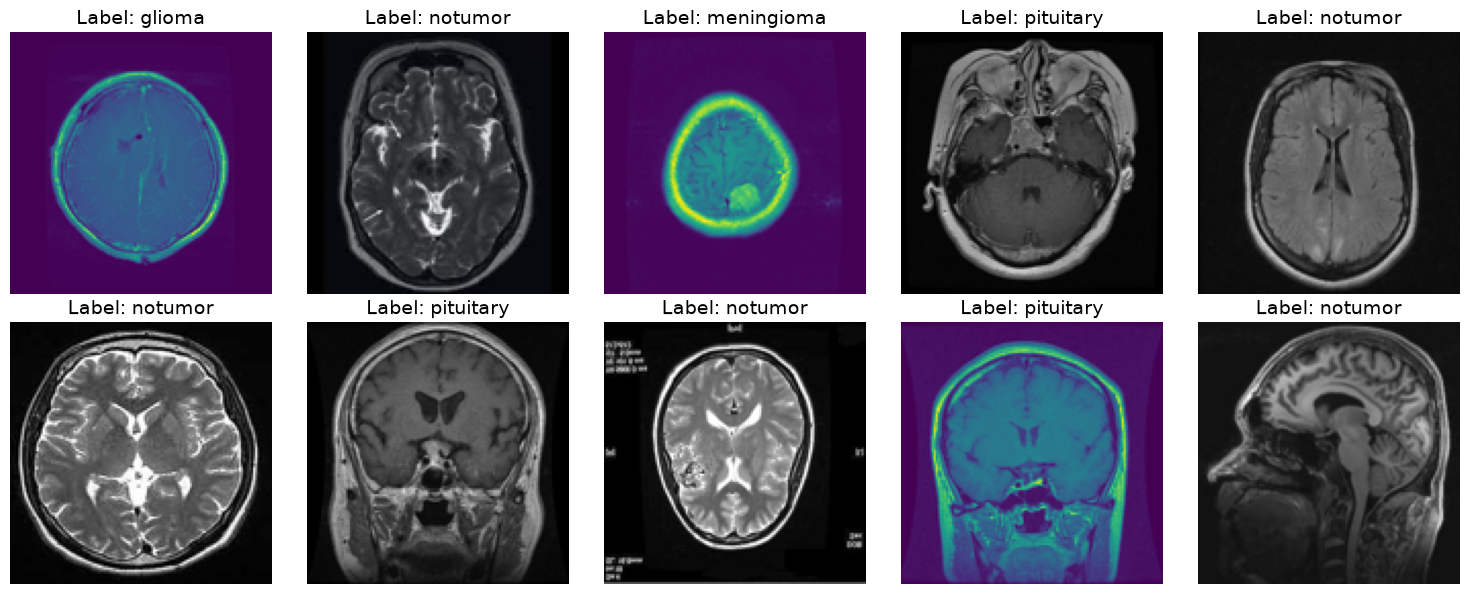

In [5]:
random_indices = random.sample(range(len(train_paths)), 10)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

for i, idx in enumerate(random_indices):
    img = Image.open(train_paths[idx])
    img = img.resize((128, 128))

    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Label: {train_labels[idx]}", fontsize=14)

plt.tight_layout()
plt.show()

## Image Preprocessing (Helper Functions)

Same philosophy as the VGG16 notebook:

* **Training images** get light random brightness/contrast augmentation, then
  are scaled to `[0,1]` — the format every model in this project receives.
* **Validation/test images are never augmented** — evaluation stays
  deterministic and reproducible.
* Labels are encoded with the fixed deployment order `CLASS_NAMES` (not
  `os.listdir`, whose order is filesystem-dependent and caused silent label
  mismatches in the original pipeline).

Architecture-specific scaling (BGR/means/`[-1,1]`/`[0,1]`) is handled **inside
the model** (next section), so the data pipeline stays identical for every
architecture in this project.


In [6]:
IMAGE_SIZE = 128  # matches the deployed app's IMAGE_SIZE (defined in imports too)


# Image augmentation function (training data only)
def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    image = np.array(image) / 255.0  # normalize to [0,1] (app-format input)
    return image


# Load images; augmentation only when `augment=True` (training)
def open_images(paths, augment=True):
    images = []
    for p in paths:
        img = load_img(p, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        images.append(augment_image(img) if augment else np.asarray(img, dtype=np.float32) / 255.0)
    return np.array(images)


# Encode labels using the fixed deployment order
def encode_labels(labels):
    return np.array([CLASS_NAMES.index(l) for l in labels], dtype=np.int32)


# Data generator for batching
def datagen(paths, labels, batch_size=32, epochs=1, augment=True):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths, augment=augment)
            batch_labels = encode_labels(labels[i:i + batch_size])
            yield batch_images, batch_labels


# Wrap the generator in a tf.data.Dataset so Keras 3 features (class_weight,
# callbacks, etc.) work; behaviour is identical to iterating datagen directly.
DATA_SIG = (
    tf.TensorSpec(shape=(None, IMAGE_SIZE, IMAGE_SIZE, 3), dtype=tf.float32),
    tf.TensorSpec(shape=(None,), dtype=tf.int32),
)


def make_ds(paths, labels, batch_size, augment=True):
    return tf.data.Dataset.from_generator(
        lambda: datagen(paths, labels, batch_size=batch_size, epochs=1, augment=augment),
        output_signature=DATA_SIG,
    ).prefetch(tf.data.AUTOTUNE)


print("Preprocessing helpers ready. IMAGE_SIZE =", IMAGE_SIZE)

Preprocessing helpers ready. IMAGE_SIZE = 128


## Class Imbalance Handling and Validation Split

The official `Training/` folder is split into a stratified **train (90%)** /
**validation (10%)** pair. The official `Testing/` folder remains the untouched
test set (no image from it is used for training or early stopping).

The split is stratified so every class is proportionally represented, and
`class_weight` compensates for the mild imbalance (`notumor` is the smallest
class in the training pool).


In [7]:
# Optional smoke subset (pipeline validation only — never for final metrics)
if SMOKE:
    train_paths, _, train_labels, _ = train_test_split(
        train_paths, train_labels,
        train_size=400, stratify=train_labels, random_state=SEED,
    )
    print("SMOKE: reduced train pool to", len(train_paths), "images")

# Stratified train / validation split (90/10)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths, train_labels,
    test_size=0.10, stratify=train_labels, random_state=SEED,
)

print(f"Train: {len(train_paths)}  |  Validation: {len(val_paths)}  |  Test: {len(test_paths)} (untouched)")

# Class weights from the training pool
y_train_int = encode_labels(train_labels)
class_weights = {
    i: round(float(w), 4)
    for i, w in enumerate(
        compute_class_weight("balanced", classes=np.arange(len(CLASS_NAMES)), y=y_train_int)
    )
}
print("Class weights:", class_weights)

SMOKE: reduced train pool to 400 images
Train: 360  |  Validation: 40  |  Test: 1600 (untouched)
Class weights: {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0}


## Model Architecture (InceptionV3)

**Preprocessing (embedded inside the model):** InceptionV3 expects inputs in `[-1,1]`, so `x*2-1` is embedded as a `Rescaling(2.0, offset=-1.0)` layer at the top of the saved model. Its native resolution is 299x299, but the deployed app resizes to 128x128 — we train at 128x128 so training and deployment match.

**Classification head** (new, trained from scratch):

* `GlobalAveragePooling2D` — pools each feature map to a single value; far
  fewer parameters than the VGG16 baseline's `Flatten`, much less overfitting.
* `Dropout(0.3)` → `Dense(256, relu)` → `Dropout(0.2)` → `Dense(4, softmax)`.

**Stage 1** freezes the entire backbone; only the head trains (learning rate
`1e-3`). **Stage 2** unfreezes the top `60 backbone layers
(BatchNorm layers stay frozen to avoid destroying pretrained statistics) and
fine-tunes at `1e-5`.


In [8]:
# Build the model: embedded preprocessing -> frozen backbone -> new head
inputs = Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name="app_input")

# InceptionV3 needs inputs scaled to [-1,1]; embed the rescaling in the model so
# the deployed app's [0,1] input keeps working.
backbone = InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
)
x = Rescaling(2.0, offset=-1.0)(inputs)   # [0,1] -> [-1,1]
x = backbone(x)

x = GlobalAveragePooling2D(name="gap")(x)
x = Dropout(0.3, name="head_dropout_1")(x)
x = Dense(256, activation="relu", name="head_dense")(x)
x = Dropout(0.2, name="head_dropout_2")(x)
outputs = Dense(len(CLASS_NAMES), activation="softmax", name="predictions")(x)

model = Model(inputs, outputs, name="InceptionV3")

# Stage 1: everything pretrained is frozen
backbone.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)

total = model.count_params()
trainable = int(sum(int(np.prod(w.shape)) for w in model.trainable_weights))
print(f"{model.name} | total params: {total:,} | trainable (stage 1): {trainable:,} | frozen: {total - trainable:,}")
model.summary()

E0000 00:00:1794420732.796237   37761 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



       0/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/87910968 ━━━━━━━━━━━━━━━━━━━━ 59:21 41us/step

   49152/87910968 ━━━━━━━━━━━━━━━━━━━━ 27:43 19us/step

   81920/87910968 ━━━━━━━━━━━━━━━━━━━━ 19:43 13us/step

  106496/87910968 ━━━━━━━━━━━━━━━━━━━━ 18:42 13us/step

... (591 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ app_input (InputLayer)          │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 2, 2, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout_1 (Dropout)        │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dense (Dense)              │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout_2 (Dropout)        │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,328,356 (85.18 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

## Training (Two-Stage Transfer Learning)

* **Stage 1 — feature extraction:** backbone frozen, head trained with
  `Adam(lr=1e-3)`.
* **Stage 2 — fine-tuning:** top backbone layers unfrozen (BatchNorm kept
  frozen), model **recompiled** with `Adam(lr=1e-5)`.

Both stages use `ModelCheckpoint` (best `val_loss` → `model.keras`),
`EarlyStopping` (restore best weights) and `ReduceLROnPlateau`.

Artifacts are written to `InceptionV3_model/` (or `smoke_runs/InceptionV3/` in smoke
mode): `model.keras`, `metrics.csv` (training history — same columns the
VGG16 pipeline used, plus validation metrics), and the evaluation outputs.


In [9]:
OUT_DIR = ("smoke_runs/InceptionV3" if SMOKE else "InceptionV3_model")
os.makedirs(OUT_DIR, exist_ok=True)

batch_size = 32
steps = int(np.ceil(len(train_paths) / batch_size))
val_steps = int(np.ceil(len(val_paths) / batch_size))
epochs_stage1 = 2 if SMOKE else 10
epochs_stage2 = 2 if SMOKE else 10

callbacks = [
    ModelCheckpoint(os.path.join(OUT_DIR, "model.keras"), monitor="val_loss", save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
]

t_stage1 = time.time()
history1 = model.fit(
    make_ds(train_paths, train_labels, batch_size=batch_size, augment=True),
    steps_per_epoch=steps,
    epochs=epochs_stage1,
    validation_data=make_ds(val_paths, val_labels, batch_size=batch_size, augment=False),
    validation_steps=val_steps,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1,
)
stage1_seconds = round(time.time() - t_stage1, 1)
print(f"Stage 1 finished in {stage1_seconds} s")

# ---- Stage 2: fine-tune the top backbone layers ----
UNFREEZE_N = 60  # top-N backbone layers (BatchNorm stays frozen)

backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = False
for layer in backbone.layers[-UNFREEZE_N:]:
    if not isinstance(layer, BatchNormalization):
        layer.trainable = True
unfrozen = sum(1 for l in backbone.layers if l.trainable)
model.compile(
    optimizer=Adam(learning_rate=1e-5),   # much smaller LR for fine-tuning
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)
print(f"Stage 2: unfrozen {unfrozen} backbone layers (of {len(backbone.layers)})")

t_stage2 = time.time()
history2 = model.fit(
    make_ds(train_paths, train_labels, batch_size=batch_size, augment=True),
    steps_per_epoch=steps,
    epochs=epochs_stage1 + epochs_stage2,
    initial_epoch=epochs_stage1,
    validation_data=make_ds(val_paths, val_labels, batch_size=batch_size, augment=False),
    validation_steps=val_steps,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1,
)
stage2_seconds = round(time.time() - t_stage2, 1)
print(f"Stage 2 finished in {stage2_seconds} s")

# Save the final (best-weights-restored) model explicitly
model.save(os.path.join(OUT_DIR, "model.keras"))

# Combined training history -> metrics.csv (same columns the VGG16 pipeline
# used, plus validation metrics and a stage column)
df1 = pd.DataFrame(history1.history); df1["stage"] = "1_feature_extraction"
df2 = pd.DataFrame(history2.history); df2["stage"] = "2_fine_tuning"
metrics_df = pd.concat([df1, df2]).reset_index(drop=True)
metrics_df.insert(0, "epoch", metrics_df.index + 1)
metrics_df.to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
print("Saved:", os.path.join(OUT_DIR, "model.keras"), "and metrics.csv")

Epoch 1/2


/home/nishanta/Projects/MRI_Detection/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794420852.307636   37761 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


 1/12 ━━━━━━━━━━━━━━━━━━━━ 2:24 13s/step - loss: 3.4410 - sparse_categorical_accuracy: 0.2812

W0000 00:00:1794420865.367632   37761 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1794420852568525745 in buffer 'PrefetchDataset/_8' sat unconsumed for 12.2919 seconds!


 2/12 ━━━━━━━━━━━━━━━━━━━━ 5s 501ms/step - loss: 6.3084 - sparse_categorical_accuracy: 0.2500

 3/12 ━━━━━━━━━━━━━━━━━━━━ 4s 484ms/step - loss: 5.5210 - sparse_categorical_accuracy: 0.2604

... (38 outputs left out)

12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 311ms/step - loss: 0.0000e+00 - sparse_categorical_accuracy: 0.0000e+00 - val_loss: 0.6660 - val_sparse_categorical_accuracy: 0.8750 - learning_rate: 1.0000e-05


Restoring model weights from the end of the best epoch: 3.


Stage 2 finished in 202.3 s


Saved: smoke_runs/InceptionV3/model.keras and metrics.csv


## Training Accuracy and Loss

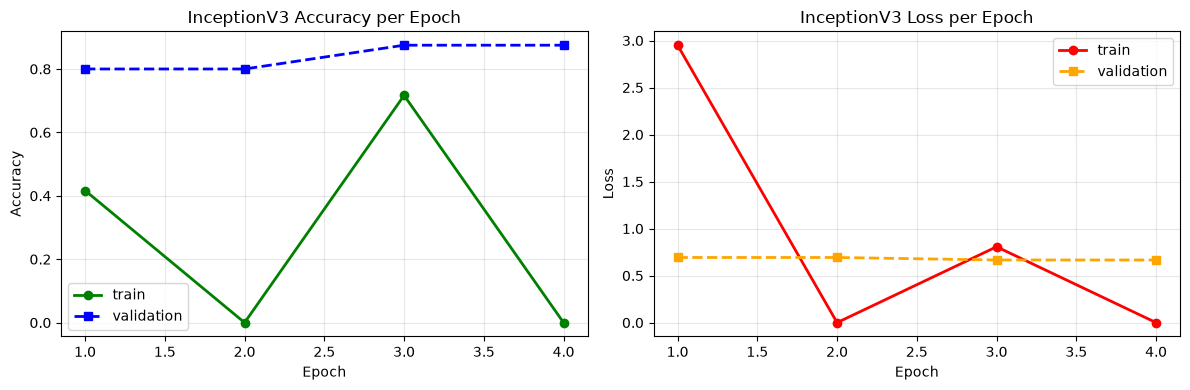

,epoch,loss,sparse_categorical_accuracy,val_loss,val_sparse_categorical_accuracy,learning_rate,stage
0,1,2.950295,0.416667,0.692758,0.800,0.00100,1_feature_extraction
1,2,0.000000,0.000000,0.692758,0.800,0.00100,1_feature_extraction
2,3,0.806755,0.716667,0.666024,0.875,0.00001,2_fine_tuning
3,4,0.000000,0.000000,0.666024,0.875,0.00001,2_fine_tuning


In [10]:
df = pd.read_csv(os.path.join(OUT_DIR, "metrics.csv"))
epoch_numbers = np.arange(1, len(df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epoch_numbers, df['sparse_categorical_accuracy'], 'o-', color='green', linewidth=2, label='train')
if 'val_sparse_categorical_accuracy' in df:
    axes[0].plot(epoch_numbers, df['val_sparse_categorical_accuracy'], 's--', color='blue', linewidth=2, label='validation')
axes[0].set_title('InceptionV3 Accuracy per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epoch_numbers, df['loss'], 'o-', color='red', linewidth=2, label='train')
if 'val_loss' in df:
    axes[1].plot(epoch_numbers, df['val_loss'], 's--', color='orange', linewidth=2, label='validation')
axes[1].set_title('InceptionV3 Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

df

## Load the Trained Model and Run Test Predictions

The model is **re-loaded from disk** (`InceptionV3_model/model.keras`) exactly like
the deployed website does (`tf.keras.models.load_model(..., compile=False)`),
then evaluated on the untouched official test set with the same deterministic
preprocessing the app uses (`/255`, no augmentation).


In [11]:
# Deterministic test preprocessing (identical to the deployed app's pipeline)
def load_test_images(paths):
    images = []
    for p in paths:
        img = load_img(p, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        images.append(np.asarray(img, dtype=np.float32) / 255.0)
    return np.array(images)


model = tf.keras.models.load_model(os.path.join(OUT_DIR, "model.keras"), compile=False)

test_images = load_test_images(test_paths)
test_labels_encoded = encode_labels(test_labels)

t0 = time.time()
test_predictions = model.predict(test_images, batch_size=32, verbose=0)
infer_seconds = time.time() - t0

y_pred = np.argmax(test_predictions, axis=1)
test_accuracy = float((y_pred == test_labels_encoded).mean())

print(f"Class order        : {CLASS_NAMES}")
print(f"Test images        : {test_images.shape}")
print(f"Prediction matrix  : {test_predictions.shape}")
print(f"Test accuracy      : {test_accuracy:.4f}")
print(f"Inference time     : {infer_seconds:.2f} s total ({infer_seconds * 1000 / len(test_paths):.2f} ms/image)")

W0000 00:00:1794421187.343559   37761 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1794421167767290154 in buffer 'PrefetchDataset' sat unconsumed for 19.5761 seconds!


Class order        : ['meningioma', 'pituitary', 'notumor', 'glioma']
Test images        : (1600, 128, 128, 3)
Prediction matrix  : (1600, 4)
Test accuracy      : 0.7250
Inference time     : 122.99 s total (76.87 ms/image)


## Classification Report

In [12]:
report = classification_report(
    test_labels_encoded,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4,
)
print("Classification Report\n")
print(report)

with open(os.path.join(OUT_DIR, "classification_report.txt"), "w") as f:
    f.write(f"Architecture: InceptionV3\n\n")
    f.write(report)

Classification Report

              precision    recall  f1-score   support

  meningioma     0.6553    0.4325    0.5211       400
   pituitary     0.6564    0.9075    0.7618       400
     notumor     0.8750    0.9100    0.8922       400
      glioma     0.7084    0.6500    0.6780       400

    accuracy                         0.7250      1600
   macro avg     0.7238    0.7250    0.7133      1600
weighted avg     0.7238    0.7250    0.7133      1600



## Confusion Matrix

Confusion Matrix (rows = true, columns = predicted)
[[173 123  27  77]
 [ 24 363   1  12]
 [ 12   6 364  18]
 [ 55  61  24 260]]


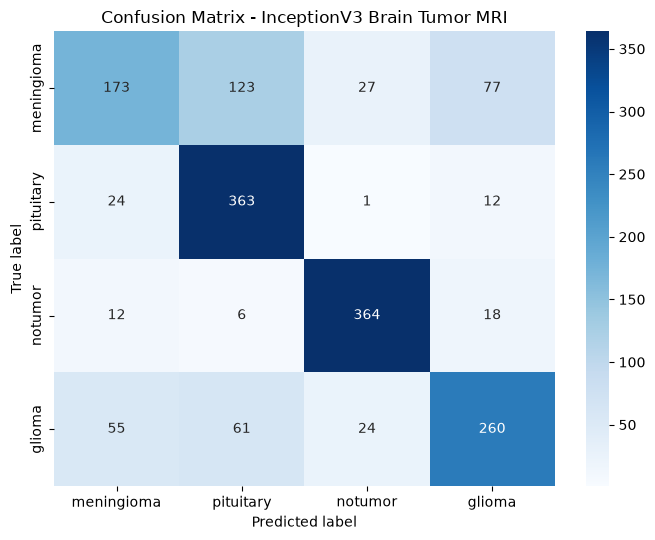

In [13]:
import seaborn as sns

conf_matrix = confusion_matrix(test_labels_encoded, y_pred)
print("Confusion Matrix (rows = true, columns = predicted)")
print(conf_matrix)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax,
)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion Matrix - InceptionV3 Brain Tumor MRI')
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=140)
plt.show()

## ROC Curve (One-vs-Rest)

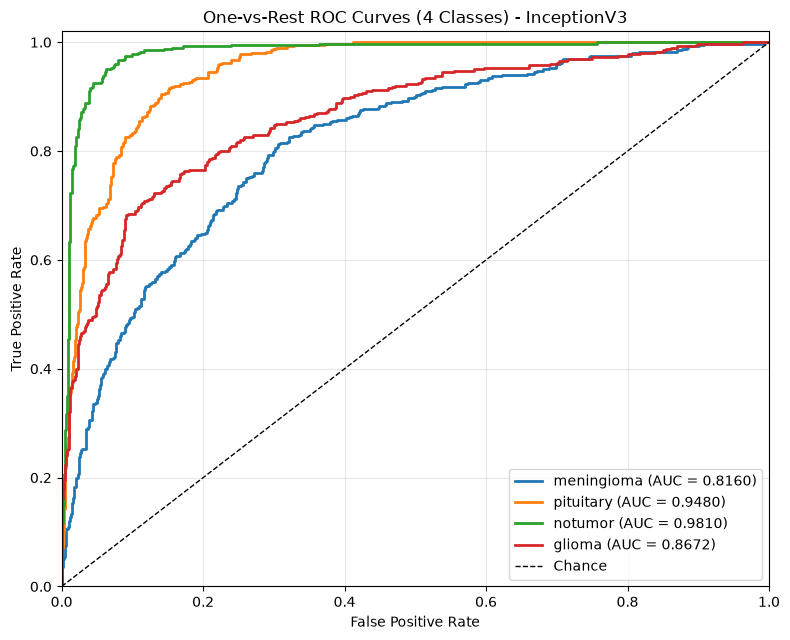

Macro-average AUC: 0.9031


In [14]:
# One-vs-rest: each class as positive against the other three
num_classes = len(CLASS_NAMES)
y_test_onehot = label_binarize(test_labels_encoded, classes=np.arange(num_classes))

per_class_auc = {}
fig, ax = plt.subplots(figsize=(8, 6.5))
for class_index, class_name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_onehot[:, class_index], test_predictions[:, class_index])
    class_auc = auc(fpr, tpr)
    per_class_auc[class_name] = float(class_auc)
    ax.plot(fpr, tpr, linewidth=2, label=f"{class_name} (AUC = {class_auc:.4f})")

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('One-vs-Rest ROC Curves (4 Classes) - InceptionV3')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "roc_curves.png"), dpi=140)
plt.show()

macro_auc = float(np.mean(list(per_class_auc.values())))
print(f"Macro-average AUC: {macro_auc:.4f}")

## Model Evaluation Summary (saved as JSON)

In [15]:
# Per-class and aggregate metrics
prec, rec, f1s, support = precision_recall_fscore_support(
    test_labels_encoded, y_pred, labels=np.arange(num_classes), zero_division=0
)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    test_labels_encoded, y_pred, labels=np.arange(num_classes), average="macro", zero_division=0
)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    test_labels_encoded, y_pred, labels=np.arange(num_classes), average="weighted", zero_division=0
)

total_params = int(model.count_params())
trainable_params = int(sum(int(np.prod(w.shape)) for w in model.trainable_weights))

eval_metrics = {
    "architecture": "InceptionV3",
    "smoke_run": SMOKE,
    "class_order": CLASS_NAMES,
    "image_size": IMAGE_SIZE,
    "test_accuracy": test_accuracy,
    "per_class": {
        CLASS_NAMES[i]: {
            "precision": float(prec[i]), "recall": float(rec[i]),
            "f1": float(f1s[i]), "support": int(support[i]),
        } for i in range(num_classes)
    },
    "macro": {"precision": float(macro_p), "recall": float(macro_r), "f1": float(macro_f1)},
    "weighted": {"precision": float(weighted_p), "recall": float(weighted_r), "f1": float(weighted_f1)},
    "auc": {"per_class": per_class_auc, "macro": macro_auc},
    "confusion_matrix": conf_matrix.tolist(),
    "params": {"total": total_params, "trainable": trainable_params},
    "unfrozen_backbone_layers_stage2": int(unfrozen),
    "training_time_seconds": {"stage1": stage1_seconds, "stage2": stage2_seconds},
    "inference_time_seconds_full_test": round(float(infer_seconds), 3),
    "inference_ms_per_image": round(float(infer_seconds) * 1000 / len(test_paths), 2),
    "epochs": {"stage1": epochs_stage1, "stage2": epochs_stage2, "ran": [len(history1.history['loss']), len(history2.history['loss'])]},
}
with open(os.path.join(OUT_DIR, "eval_metrics.json"), "w") as f:
    json.dump(eval_metrics, f, indent=2)

import json as _json  # already imported style; keep namespace clean
with open(os.path.join(OUT_DIR, "eval_metrics.json")) as f:
    print(_json.dumps({k: eval_metrics[k] for k in
        ["test_accuracy", "macro", "weighted", "auc", "params"]}, indent=2))

print("\nFiles in", OUT_DIR)
for f_ in sorted(os.listdir(OUT_DIR)):
    print("  ", f_)

{
  "test_accuracy": 0.725,
  "macro": {
    "precision": 0.7237923566563238,
    "recall": 0.725,
    "f1": 0.7132530321629875
  },
  "weighted": {
    "precision": 0.7237923566563238,
    "recall": 0.725,
    "f1": 0.7132530321629875
  },
  "auc": {
    "per_class": {
      "meningioma": 0.8159854166666667,
      "pituitary": 0.9480374999999999,
      "notumor": 0.9809833333333334,
      "glioma": 0.8672312499999999
    },
    "macro": 0.903059375
  },
  "params": {
    "total": 22328356,
    "trainable": 11060484
  }
}

Files in smoke_runs/InceptionV3
   classification_report.txt
   confusion_matrix.png
   eval_metrics.json
   metrics.csv
   model.keras
   roc_curves.png


## Which Classes Are Hard?

Look at the per-class recall and the confusion matrix above. Typical patterns
for this dataset (confirm with your numbers):

* **glioma ↔ meningioma** confusion is the most common error — both appear as
  irregular bright masses in different regions, and glioma boundaries are
  notoriously diffuse (infiltrative growth), so the two classes share visual
  signatures.
* **notumor** is usually easy (no bright mass) but suffers when a small
  enhancement or imaging artefact resembles a lesion; it is also the smallest
  class, which the class weights partially compensate for.
* **pituitary** tumours are small and centrally located — usually the easiest
  class, with high recall.

If one class has clearly lower F1, options are: more epochs of stage-2
fine-tuning, stronger augmentation for that class, or targeted data collection.
Never "clean" difficult test samples out of the evaluation set.

## Conclusion

InceptionV3's factorized convolutions make it cheaper than ResNet50 despite a similar parameter count. At 128x128 (below its native 299) it may lose some accuracy — the metrics above show how much.

**Deployment:** point the website at this model — for the Flask app set
`MODEL_PATH=InceptionV3_model/model.keras` (or edit the default in `app.py`), for
Streamlit set `MODEL_PATH` / the model folder. **No preprocessing changes are
needed**: the architecture-specific input transform (channel order, mean
subtraction, `[-1,1]` scaling) is embedded inside the saved `model.keras`, which
accepts exactly the `[0,1]` RGB 128x128 input the apps already produce.
